# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: NoordelikeWerke
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 1707 | Val: 415 | Test: 405


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 6.83e-05 | train loss 1.1060 acc 0.499 | val loss 0.9452 acc 0.540 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 6.83e-05 | train loss 1.0303 acc 0.539 | val loss 0.9657 acc 0.576


[ResNet-18 (scratch)] Epoch   3/100 | LR: 6.83e-05 | train loss 0.9117 acc 0.571 | val loss 0.8679 acc 0.607 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 6.83e-05 | train loss 0.9061 acc 0.565 | val loss 0.8547 acc 0.629 *


...

[ResNet-18 (scratch)] Epoch  38/100 | LR: 6.83e-06 | train loss 0.2563 acc 0.867 | val loss 0.4870 acc 0.829


[ResNet-18 (scratch)] Epoch  39/100 | LR: 6.83e-06 | train loss 0.2645 acc 0.876 | val loss 0.4972 acc 0.819


[ResNet-18 (scratch)] Epoch  40/100 | LR: 6.83e-06 | train loss 0.2280 acc 0.885 | val loss 0.4878 acc 0.829


[ResNet-18 (scratch)] Epoch  41/100 | LR: 6.83e-06 | train loss 0.2393 acc 0.886 | val loss 0.5096 acc 0.814


[ResNet-18 (scratch)] Epoch  42/100 | LR: 6.83e-06 | train loss 0.2264 acc 0.875 | val loss 0.4800 acc 0.827

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 42.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.4593)


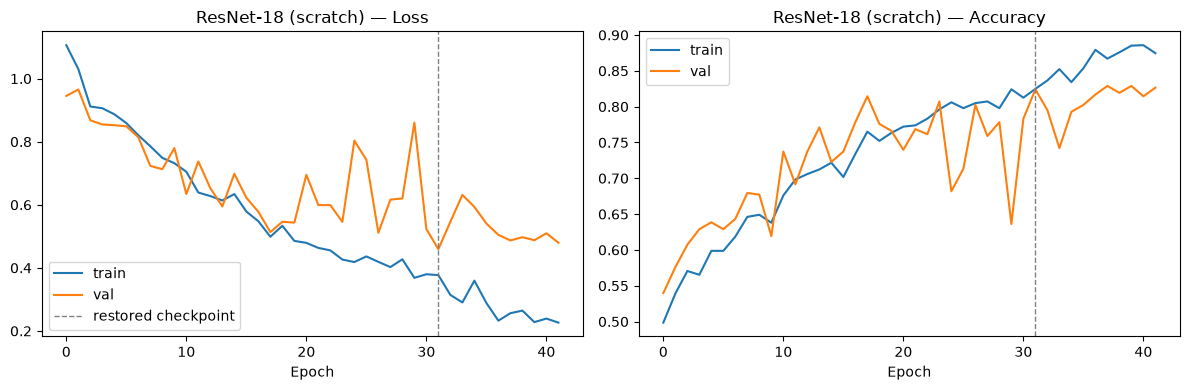

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.837


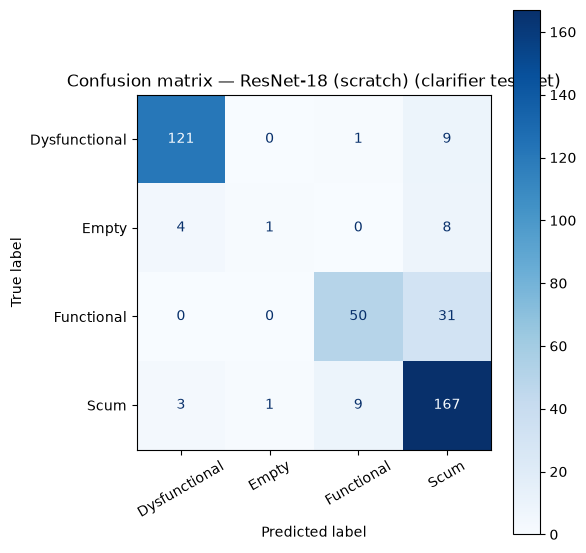

               precision    recall  f1-score   support

Dysfunctional      0.945     0.924     0.934       131
        Empty      0.500     0.077     0.133        13
   Functional      0.833     0.617     0.709        81
         Scum      0.777     0.928     0.846       180

     accuracy                          0.837       405
    macro avg      0.764     0.636     0.656       405
 weighted avg      0.834     0.837     0.824       405



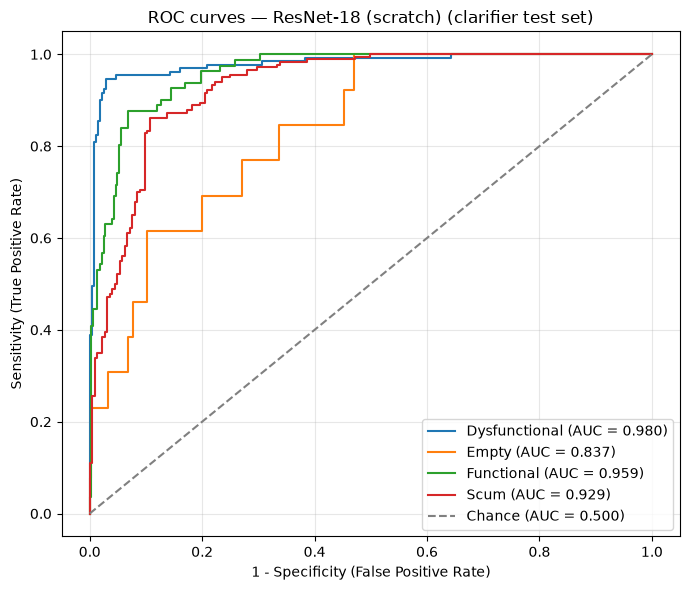

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.980
  Empty          : 0.837
  Functional     : 0.959
  Scum           : 0.929

Mean AUC (over 4/4 classes with test examples): 0.927


(np.float64(0.837037037037037),
 {'Dysfunctional': 0.9802473951078176,
  'Empty': 0.8373233908948194,
  'Functional': 0.9590001524157903,
  'Scum': 0.9294814814814815})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_scratch_NoordelikeWerke.pkl
Saved model weights to ../models/pad/clarifier_aug/clarifier_resnet18_scratch_NoordelikeWerke.pt
